# Impact of nudging on the land state

**Runs: new chain (after the CO₂ fix), 2001–2014.** Updated 2026-11-03. The old-chain version (CTRL `-20260925`, LCC `-20261005`, 2001–2009) is in git (commit `2f2e672`); its figures and tables are in `impact_of_nudging_on_land_outputs/pre_co2_fix/`.

**Question.** H2OSOI, TSOI and TWS at 1 m jump when a free coupled spin-up hands over to a nudged run. This happens in both branches (CTRL and LCC). This notebook asks:
1. **How large is the effect of nudging itself?** PD has a clean test: the **met run** `MET` (`NF2000norbc_tropstratchem_met_f19_f19_20260422`).
   - It is the free continuation of `PD_spinup` (same forcing, 2000–2014), and it supplied the nudging winds.
   - `MET − PD_spinup` is the free decade-to-decade difference (variability or residual drift).
   - New in this chain: `CTRL_PD` does **not** start from `PD_spinup` directly. Its land went through a 100-yr land-only spin-up and a 20-yr coupled spin-up (`CTRL_PD_spinup`). So `CTRL_PD − MET` mixes the nudging effect with the land spin-up. §3 removes the land spin-up part using `CTRL_PD_spinup − PD_spinup`.
2. **How large is the FUT jump?** By design, FUT runs are nudged to the **PD** winds (user decision, 2026-10-22). No free FUT met run exists, so the FUT jump cannot be split into its parts.
3. **Do CTRL and LCC drift in the same way during the nudged years?** If they do, the drift cancels in LCC − CTRL.

**Lineage (new chain, the same in CTRL and LCC):** shared coupled spin-up (`PD_spinup` / `FUT_spinup`, land years 1–20) → land-only spin-up (100 yr, years 21–120, left out: no atmosphere) → coupled spin-up (`CTRL_*_spinup` / `LCC_*_spinup`, years 121–140) → nudged run (`CTRL_*` / `LCC_*`, 2000–2014 = years 141–155).

**Nudging set-up** (`cases-scripts/cases-setup.sh: setup_nudging_data`): u, v and PS only (`met_nudge_only_uvps`), relaxation time 6 h, the same met file for all nudged runs. Checked from `CaseDocs/atm_in` in §1.

**Variables:**
- short-term: TWS, H2OSOI and TSOI at 1.06 m;
- land drivers: TSA (2 m air temperature), precipitation (RAIN + SNOW), FSDS, FLDS, latent and sensible heat, transpiration (QVEGT), runoff, snow water (H2OSNO).

**Regions:** modified cells, >45°N unmodified, tropics 30°S–30°N, global land. Annual means are weighted by month length; spatial weights are area × landfrac. The first nudged year (2000) is dropped as spin-up.

**Figures:** project palette (`plotting/palette.py`, copied hexes), Cantarell font, maps RdBu_r with ≥ 9 colourbar ticks, LCC-modified cells outlined in dark grey.

Evidence tags: **(a)** verified · **(b)** inference · **(c)** unverified. Annual means are cached in `impact_of_nudging_on_land_outputs/cache/`.

In [1]:
import os
os.environ.setdefault('HDF5_USE_FILE_LOCKING', 'FALSE')  # before netCDF4/xarray import: HDF5 locking on /cluster/home corrupted cache files
from pathlib import Path
import re
import pickle
import warnings
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
import numpy as np
import pandas as pd
import xarray as xr
import netCDF4
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import cartopy.crs as ccrs
from scipy import stats

ARCHIVE = Path('/nird/datapeak/NS9188K/adelez/BRL-FRST-XPSN_archive')
CASE_ROOT = Path('~/cases/BRL_FRST_XPSN').expanduser()
MASK_FILE = Path('../lcc-modified-cells/modified_cells.nc')
OUT = Path('impact_of_nudging_on_land_outputs')
CACHE = OUT / 'cache'  # regenerable annual-mean .nc
CACHE.mkdir(parents=True, exist_ok=True)
REBUILD_CACHE = False
N_WORKERS = 8

# stage (run alias), period, branch, case, kind, start (x-axis offset in land years since the shared starting state)
STAGES = pd.DataFrame([
    ('PD_spinup',       'PD',  'shared', 'NF2000norbc_tropstratchem_spinup_f19_f19',                    'free',              0),
    ('MET',             'PD',  'MET',    'NF2000norbc_tropstratchem_met_f19_f19_20260422',              'free (met source)', 20),
    ('CTRL_PD_spinup',  'PD',  'CTRL',   'NF2000norbc_tropstratchem_spinup_ctrl_f19_f19-20261026',      'free',              120),
    ('CTRL_PD',         'PD',  'CTRL',   'NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261029',        'nudged',            140),
    ('LCC_PD_spinup',   'PD',  'LCC',    'NF2000norbc_tropstratchem_spinup_lcc_f19_f19-20261025',       'free',              120),
    ('LCC_PD',          'PD',  'LCC',    'NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261028',         'nudged',            140),
    ('FUT_spinup',      'FUT', 'shared', 'NF2100ssp585norbc_tropstratchem_spinup_f19_f19-3',            'free',              0),
    ('CTRL_FUT_spinup', 'FUT', 'CTRL',   'NF2100ssp585norbc_tropstratchem_spinup_ctrl_f19_f19-20261025', 'free',             120),
    ('CTRL_FUT',        'FUT', 'CTRL',   'NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20261028',  'nudged',            140),
    ('LCC_FUT_spinup',  'FUT', 'LCC',    'NF2100ssp585norbc_tropstratchem_spinup_lcc_f19_f19-20261025', 'free',              120),
    ('LCC_FUT',         'FUT', 'LCC',    'NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f19-20261028',   'nudged',            140),
], columns=['stage', 'period', 'branch', 'case', 'kind', 'start']).set_index('stage')
# The land-only spin-ups (land years 21-120) are left out: no atmosphere, so not relevant for nudging.

SHORT = ['TWS', 'H2OSOI_1m', 'TSOI_1m']
DRIVERS = ['TSA', 'PRECIP', 'FSDS', 'FLDS', 'EFLX_LH_TOT', 'FSH', 'QVEGT', 'QRUNOFF', 'H2OSNO']
VARS = SHORT + DRIVERS
SOIL = {'H2OSOI_1m': 'H2OSOI', 'TSOI_1m': 'TSOI'}
SOIL_INDEX = 8  # levgrnd[8] = 1.06 m; levsoi = first 20 levgrnd levels (asserted)
PER_DAY = {'PRECIP', 'QVEGT', 'QRUNOFF'}  # mm/s -> mm/day for display
NUDGED_YEARS = (2001, 2014)  # 2000 dropped as spin-up
FREE_YEARS = 10  # last years of a free spin-up used as its reference

# Project palette (src/boreal_forest_expansion/plotting/palette.py, user 2026-11-03), copied: notebook is self-contained
TEAL, NAVY, PLUM, RED, ORANGE, GOLD = '#5D9A92', '#2C3990', '#9A4A84', '#BC423E', '#DE7A3A', '#EBC45C'
LIGHT_GREY, INK = '#CCCCCC', '0.15'
COLOR = {'shared': INK, 'MET': PLUM, 'CTRL': NAVY, 'LCC': RED}  # CTRL navy, LCC red (project rule)
plt.rcParams['font.family'] = 'Cantarell'  # project font (plotting/style.py); sizes kept small for the dense grids

plt.rcParams['hatch.color'] = INK
plt.rcParams['hatch.linewidth'] = 0.4

def hatch_nonsig(ax, lat, lon, sig, land):
    # hatch land cells that are NOT significant (p >= 0.05); cyclic column added so the hatching closes at the dateline
    ns = np.where(land & ~sig, 1.0, 0.0)
    ns = np.concatenate([ns, ns[:, :1]], axis=1)
    lon_c = np.append(lon, lon[0] + 360)
    ax.contourf(lon_c, lat, ns, levels=[0.5, 1.5], colors='none', hatches=['////'], transform=ccrs.PlateCarree())

def sym_ticks(ax_cbar, lim, n=9):
    # >5 colourbar ticks when they fit (user 2026-10-28); symmetric around 0
    ax_cbar.locator = mticker.MaxNLocator(n, symmetric=True)
    ax_cbar.update_ticks()

## 1. Nudging set-up per case (from `CaseDocs/atm_in`)

In [2]:
def namelist(case, key, name='atm_in'):
    for root in (CASE_ROOT, CASE_ROOT / 'BRL_FRST_XPSN_archive'):
        f = root / case / 'CaseDocs' / name
        if f.is_file():
            m = re.search(rf'^\s*{key}\s*=\s*(.+?)\s*$', f.read_text(), re.M)
            return m.group(1).strip("'") if m else 'not set'
    return 'no CaseDocs'

setup = pd.DataFrame([dict(stage=s, kind=r.kind,
                           met_data_file=Path(namelist(r.case, 'met_data_file')).name,
                           met_nudge_only_uvps=namelist(r.case, 'met_nudge_only_uvps'),
                           met_rlx_time=namelist(r.case, 'met_rlx_time'))
                      for s, r in STAGES.iterrows()]).set_index('stage')
setup.to_csv(OUT / 'nudging_setup.csv')
display(setup)

,kind,met_data_file,met_nudge_only_uvps,met_rlx_time
stage,,,,
PD_spinup,free,not set,not set,not set
MET,free (met source),not set,not set,not set
CTRL_PD_spinup,free,not set,not set,not set
CTRL_PD,nudged,NF2000norbc_tropstratchem_met_f19_f19_20260422...,.true.,6
LCC_PD_spinup,free,not set,not set,not set
LCC_PD,nudged,NF2000norbc_tropstratchem_met_f19_f19_20260422...,.true.,6
FUT_spinup,free,not set,not set,not set
CTRL_FUT_spinup,free,not set,not set,not set
CTRL_FUT,nudged,NF2000norbc_tropstratchem_met_f19_f19_20260422...,.true.,6


## Loading annual means

Files are read with plain `netCDF4`, 8 at a time (~0.3 s per file on NIRD). Each `time_bounds` interval goes to its midpoint year, and incomplete years are dropped. Soil fields are taken at 1.06 m.

In [3]:
def hist_files(case):
    files = sorted((ARCHIVE / case / 'lnd/hist').glob('*.clm2.h0.*.nc'))
    if not files:
        raise FileNotFoundError(f'No clm2.h0 files for {case}')
    return files

def read_file(path):
    with netCDF4.Dataset(path) as d:
        t = d['time']
        assert t.calendar == 'noleap' and re.fullmatch(r'days since \d{4}-01-01( 00:00:00)?', t.units), (path, t.units)
        bounds = d['time_bounds'][:].astype(float)
        mid = bounds.mean(1)
        out = dict(mid=mid, year=int(t.units.split()[2][:4]) + np.floor(mid / 365).astype(int),
                   days=bounds[:, 1] - bounds[:, 0])
        get = lambda v: np.ma.filled(d[v][:].astype(float), np.nan)
        for v in VARS:
            if v in d.variables:
                out[v] = get(v)
        if {'RAIN', 'SNOW'} <= set(d.variables):
            out['PRECIP'] = get('RAIN') + get('SNOW')
        for new, old in SOIL.items():
            assert abs(float(d['levgrnd'][SOIL_INDEX]) - 1.06) < 0.01, f'{path}: soil levels changed'
            out[new] = np.ma.filled(d[old][:, SOIL_INDEX].astype(float), np.nan)
    return out

def annual_means(case):
    files = hist_files(case)
    try:
        with ProcessPoolExecutor(N_WORKERS, mp_context=mp.get_context('fork')) as pool:
            parts = list(pool.map(read_file, files))
    except pickle.PicklingError:  # cells exec'd outside a kernel: read serially
        parts = [read_file(f) for f in files]
    mid = np.concatenate([p['mid'] for p in parts])
    if len(np.unique(mid)) != len(mid):
        raise ValueError(f'{case}: duplicated time steps')
    year = np.concatenate([p['year'] for p in parts])
    days = np.concatenate([p['days'] for p in parts])
    keep = [y for y in np.unique(year) if abs(days[year == y].sum() - 365) < 0.5]
    with netCDF4.Dataset(files[0]) as d:
        coords = dict(lat=d['lat'][:].data, lon=d['lon'][:].data)
        grid = {v: (('lat', 'lon'), np.ma.filled(d[v][:].astype(float), np.nan)) for v in ('area', 'landfrac')}
        units = {v: d[SOIL.get(v, 'RAIN' if v == 'PRECIP' else v)].units for v in VARS
                 if SOIL.get(v, 'RAIN' if v == 'PRECIP' else v) in d.variables}
    data = {}
    for v in [v for v in VARS if all(v in p for p in parts)]:
        x = np.concatenate([p[v] for p in parts])
        rows = []
        for y in keep:
            sel = year == y
            total = np.nansum(x[sel] * days[sel][:, None, None], 0)
            total[np.isnan(x[sel]).all(0)] = np.nan
            rows.append(total / days[sel].sum())
        data[v] = (('year', 'lat', 'lon'), np.stack(rows), {'units': units.get(v, '?')})
    return xr.Dataset({**data, **grid}, coords=dict(year=keep, **coords))

def load_stage(stage):
    path = CACHE / f'annual_{stage}.nc'
    if path.is_file() and not REBUILD_CACHE:
        try:
            with xr.open_dataset(path) as ds:
                return ds.load()
        except OSError:
            print(f'{path.name}: unreadable cache, rebuilding')
    ann = annual_means(STAGES.loc[stage, 'case'])
    tmp = path.with_name(path.stem + '.tmp.nc')
    ann.to_netcdf(tmp)
    os.replace(tmp, path)
    return ann

ANN = {stage: load_stage(stage) for stage in STAGES.index}
ref = ANN['CTRL_PD']
for stage, a in ANN.items():
    assert np.array_equal(a.lat, ref.lat) and np.array_equal(a.lon, ref.lon), stage
    assert np.allclose(a.landfrac, ref.landfrac, equal_nan=True), stage
print(pd.Series({s: f"{int(a.year[0])}–{int(a.year[-1])} ({a.sizes['year']} yr); missing: "
                    f"{', '.join(v for v in VARS if v not in a) or '-'}" for s, a in ANN.items()}).to_string())

PD_spinup               1–20 (20 yr); missing: -
MET                2000–2014 (15 yr); missing: -
CTRL_PD_spinup          1–20 (20 yr); missing: -
CTRL_PD            2000–2014 (15 yr); missing: -
LCC_PD_spinup           1–20 (20 yr); missing: -
LCC_PD             2000–2014 (15 yr); missing: -
FUT_spinup              1–20 (20 yr); missing: -
CTRL_FUT_spinup         1–20 (20 yr); missing: -
CTRL_FUT           2000–2014 (15 yr); missing: -
LCC_FUT_spinup          1–20 (20 yr); missing: -
LCC_FUT            2000–2014 (15 yr); missing: -


In [4]:
mask = xr.open_dataset(MASK_FILE).modified.astype(bool)
assert np.allclose(mask.lat, ref.lat) and np.allclose(mask.lon, ref.lon)
mask = mask.assign_coords(lat=ref.lat, lon=ref.lon)
LAND = ref.landfrac > 0
LAT = ref.lat.broadcast_like(LAND)
REGIONS = {
    'modified cells': LAND & mask,
    '>45N unmodified': LAND & (LAT > 45) & ~mask,
    'tropics 30S-30N': LAND & (abs(LAT) <= 30),
    'global land': LAND,
}
W = ref.area * ref.landfrac

def scaled(stage, v):
    field = ANN[stage][v]
    return field * 86400 if v in PER_DAY else field

def units_of(v):
    stage = next(s for s in STAGES.index if v in ANN[s])
    return 'mm/day' if v in PER_DAY else ANN[stage][v].attrs.get('units', '?')

def regional_mean(field, region):
    w = W.where(REGIONS[region] & np.isfinite(field))
    return (field * w).sum(('lat', 'lon')) / w.sum(('lat', 'lon'))

SERIES = {(s, r, v): regional_mean(scaled(s, v), r) for s in STAGES.index for r in REGIONS for v in VARS if v in ANN[s]}

def window(stage):
    # Reference years: nudged runs and the met run use NUDGED_YEARS; free spin-ups their last FREE_YEARS
    a = ANN[stage]
    if STAGES.loc[stage, 'kind'] == 'free':
        return slice(int(a.year[-FREE_YEARS]), int(a.year[-1]))
    return slice(*NUDGED_YEARS)

def xaxis(stage, years):
    return STAGES.loc[stage, 'start'] + (years - int(ANN[stage].year[0]) + 1)

## 2. Free → nudged along the lineage

Dark grey = shared free spin-up, plum dotted = `MET` (free, the source of the nudging winds), navy = CTRL, red = LCC. Each branch is a free coupled spin-up (land years 121–140) followed by the nudged run (141–155). Second figure: the nudged runs and MET on the same calendar years (2000–2014), all regions; colour = branch, solid = PD, dashed = FUT; grey band = 2000, dropped as spin-up.

Dotted verticals (first figure) mark the start of the land-only spin-up (left out, years 21–120) and the free → nudged hand-over.

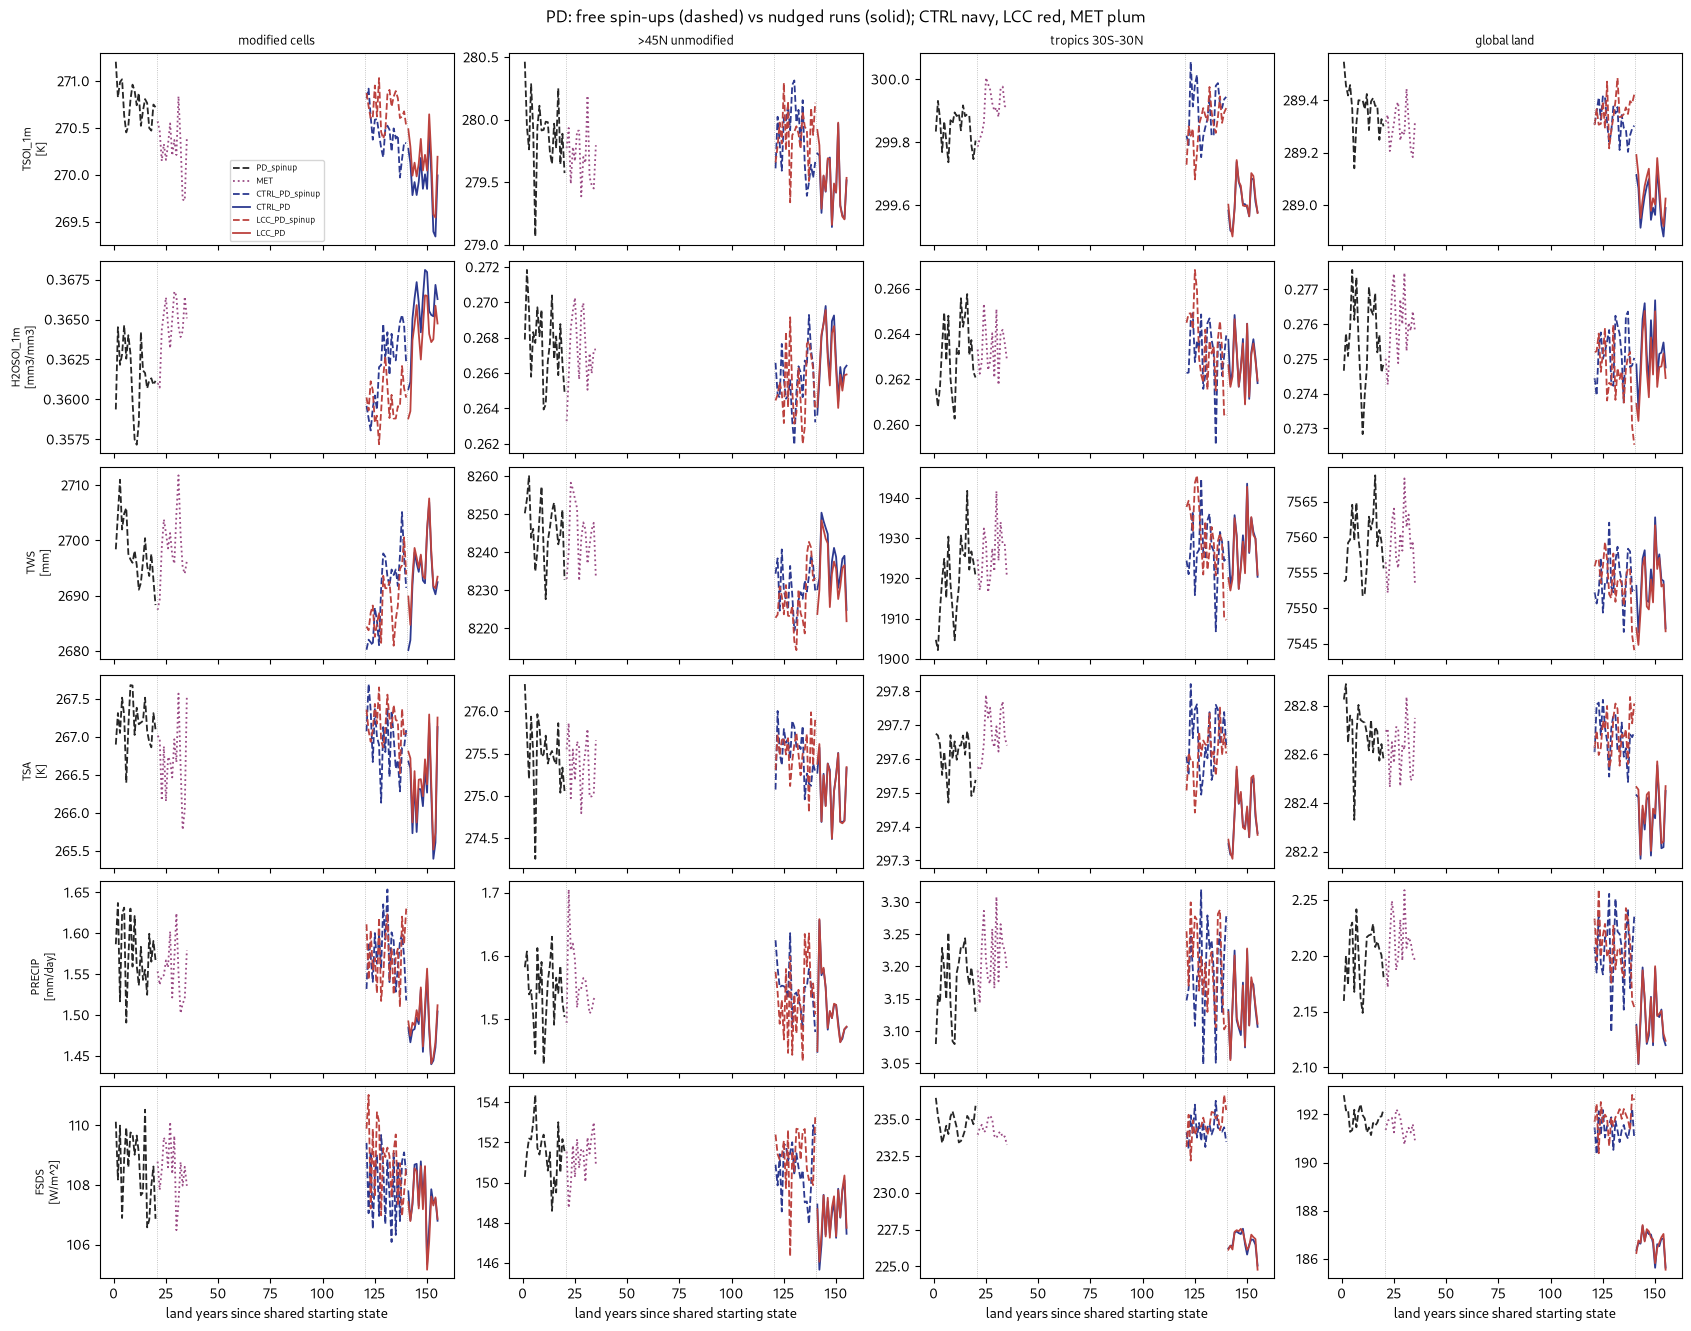

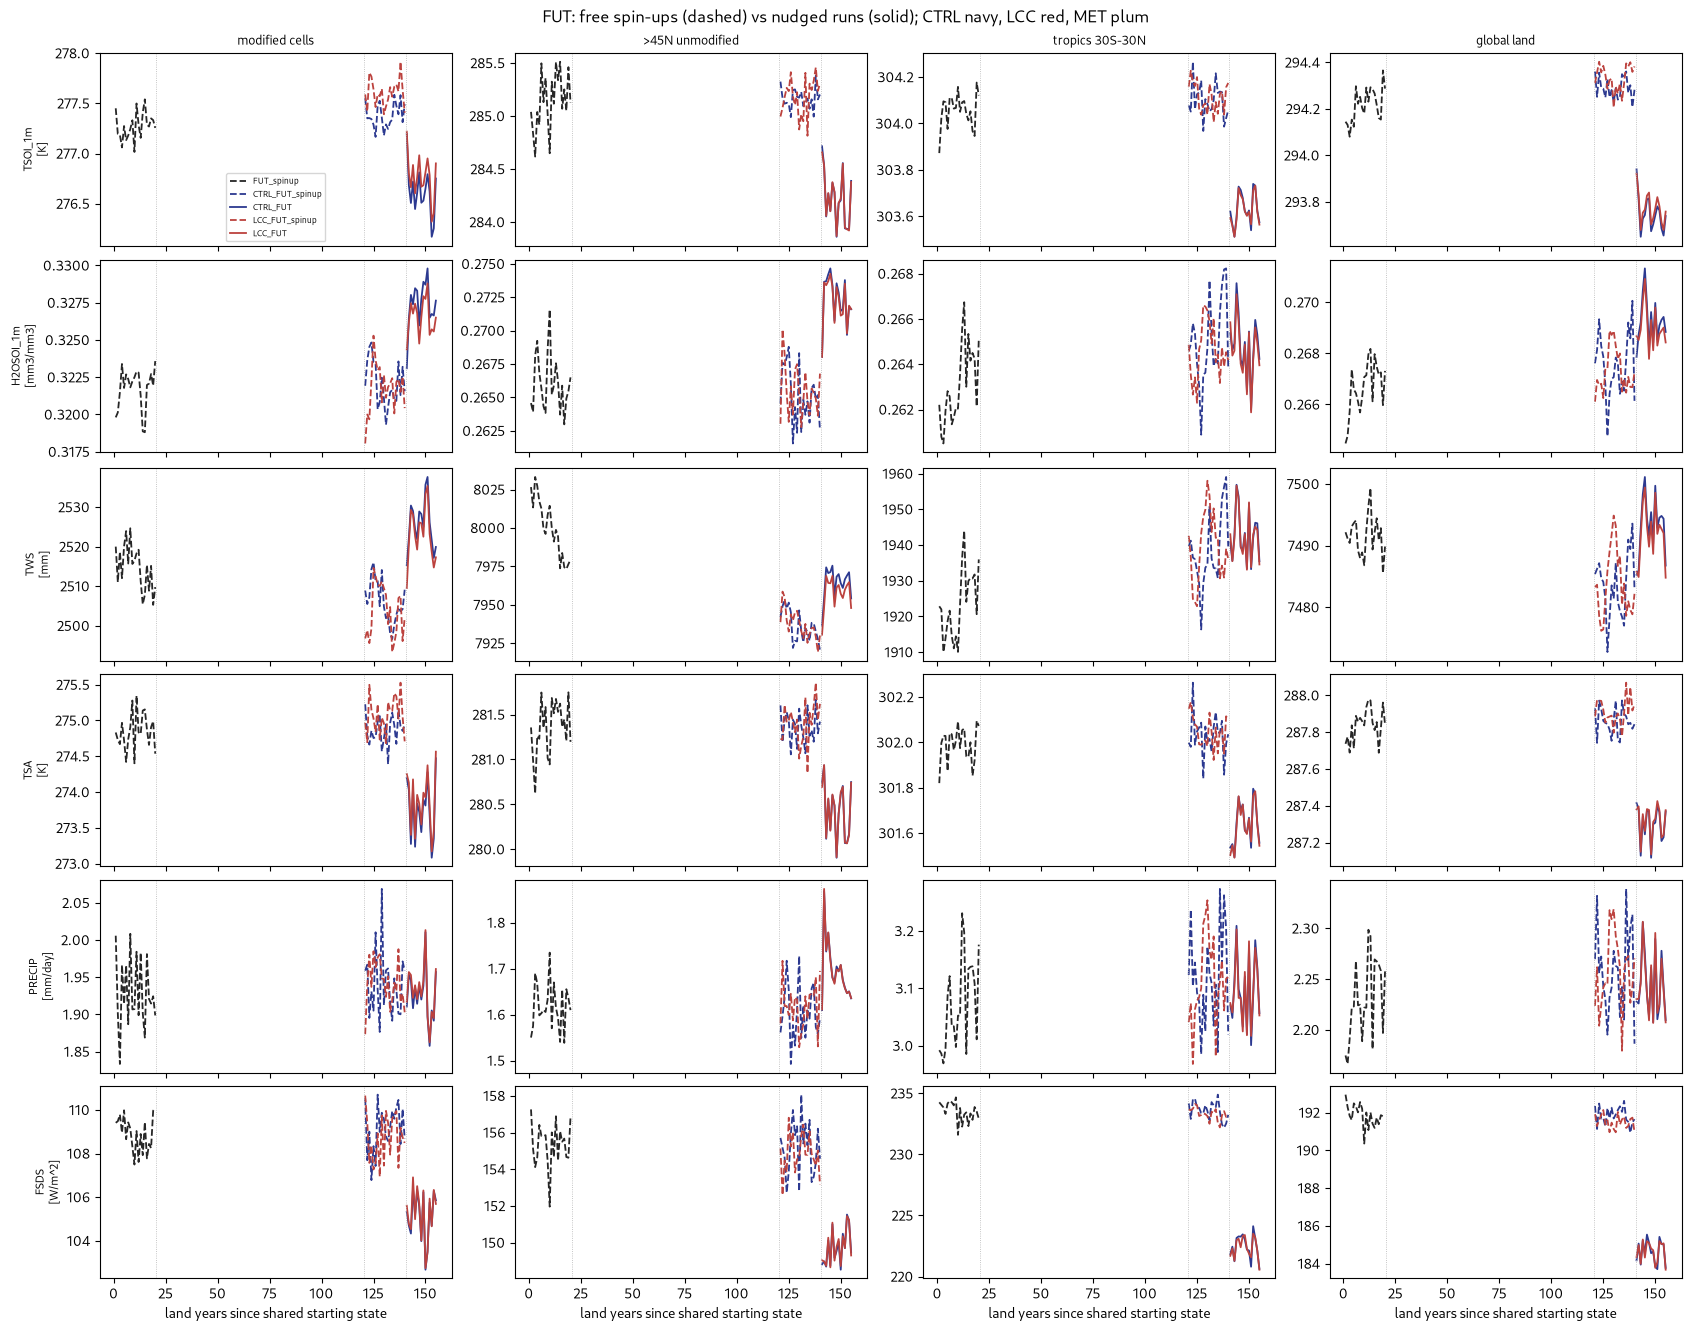

In [5]:
PLOT_VARS = ['TSOI_1m', 'H2OSOI_1m', 'TWS', 'TSA', 'PRECIP', 'FSDS']
for period in ('PD', 'FUT'):
    group = STAGES[STAGES.period == period]
    fig, axes = plt.subplots(len(PLOT_VARS), len(REGIONS), figsize=(4.2 * len(REGIONS), 2.2 * len(PLOT_VARS)),
                             sharex=True, layout='constrained')
    for i, v in enumerate(PLOT_VARS):
        for j, region in enumerate(REGIONS):
            ax = axes[i, j]
            for stage, s in group.iterrows():
                if (stage, region, v) in SERIES:
                    y = SERIES[stage, region, v]
                    ax.plot(xaxis(stage, y.year), y, color=COLOR[s.branch], lw=1.3,
                            ls=':' if s.branch == 'MET' else ('-' if 'nudged' in s.kind else '--'), label=stage)
            for x in (20.5, 120.5, 140.5):
                ax.axvline(x, color='0.7', lw=0.6, ls=':')
            if i == 0:
                ax.set_title(region, fontsize=9)
            if j == 0:
                ax.set_ylabel(f'{v}\n[{units_of(v)}]', fontsize=8)
    axes[0, 0].legend(fontsize=6)
    for ax in axes[-1]:
        ax.set_xlabel('land years since shared starting state')
    fig.suptitle(f'{period}: free spin-ups (dashed) vs nudged runs (solid); CTRL navy, LCC red, MET plum')
    fig.savefig(OUT / f'fig1_lineage_{period}.png', dpi=150)
    plt.show()

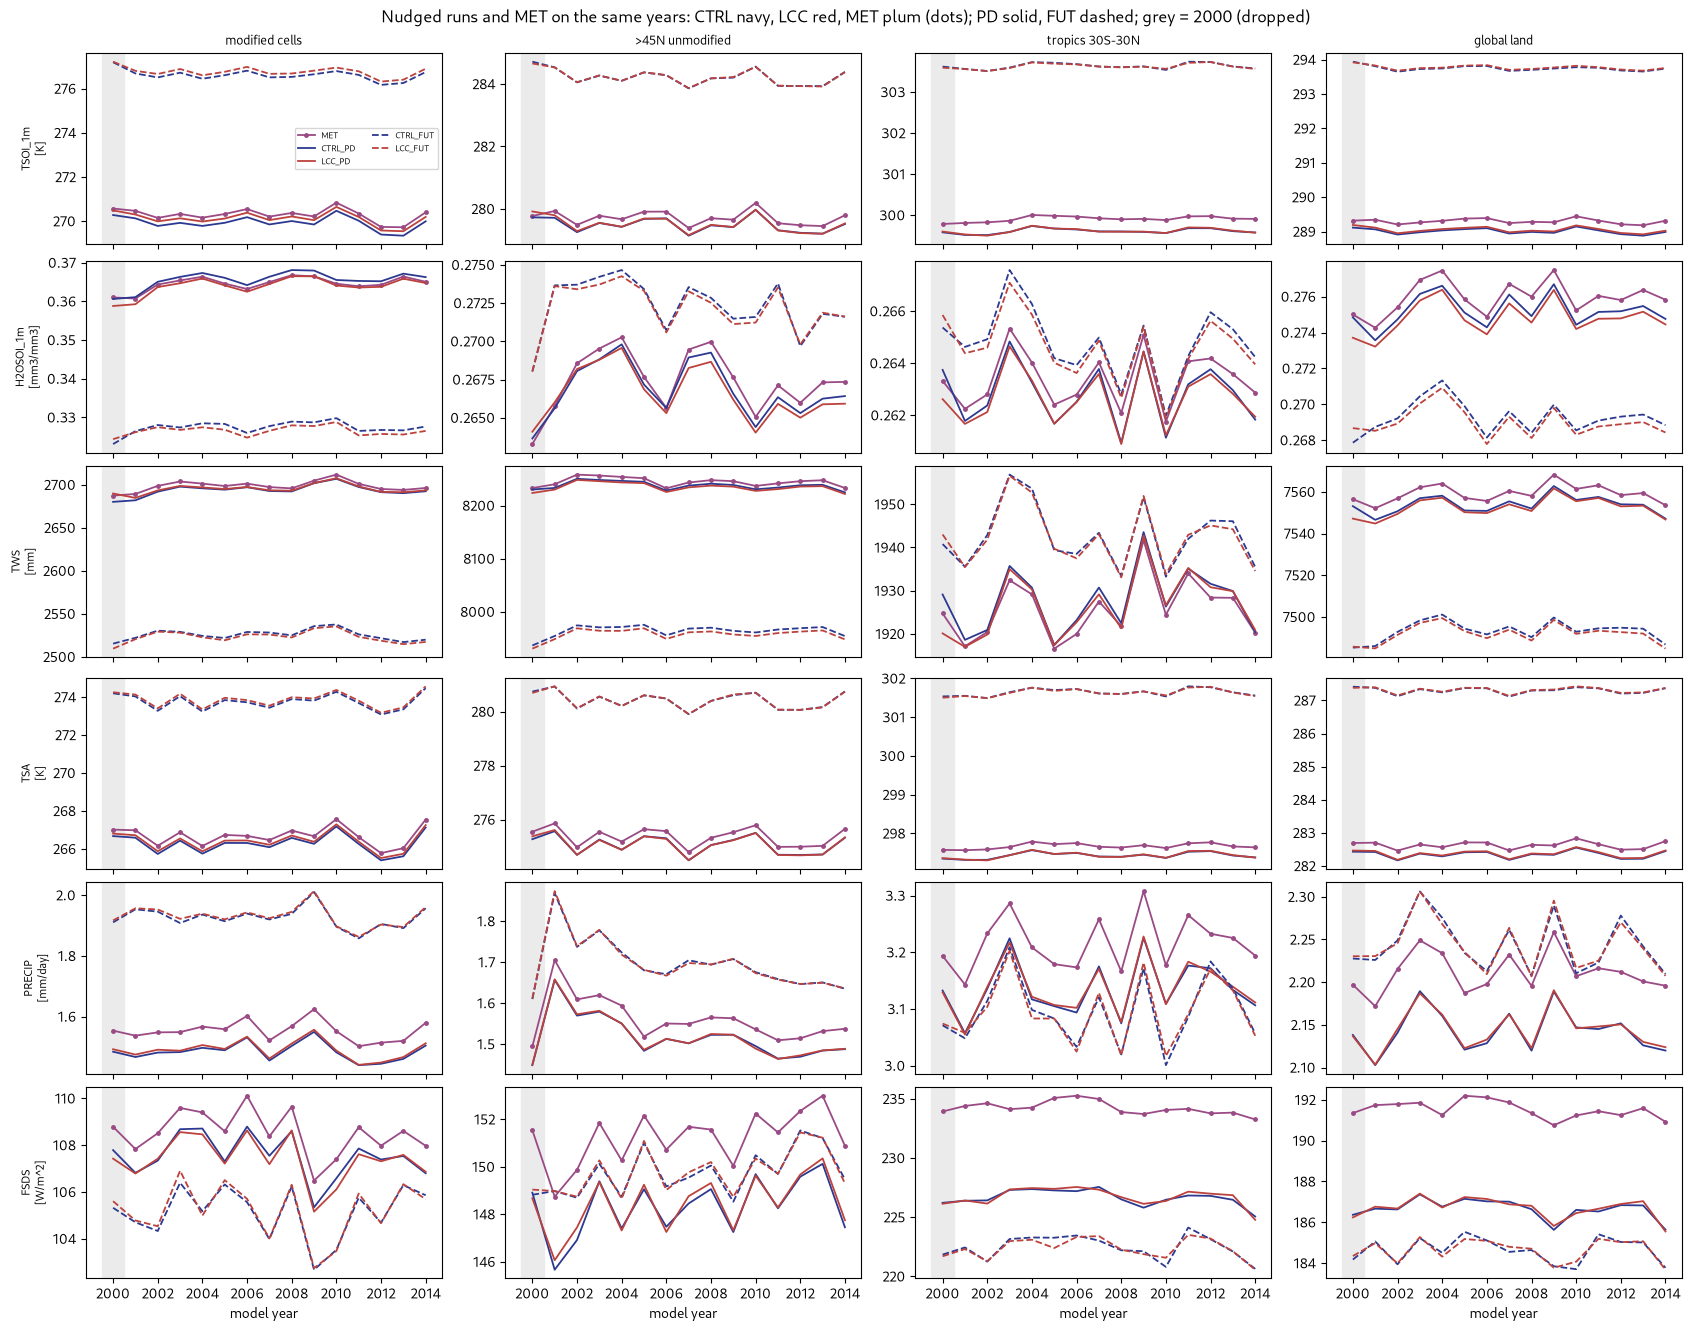

In [6]:
SAME_YEARS = ['MET', 'CTRL_PD', 'LCC_PD', 'CTRL_FUT', 'LCC_FUT']
fig, axes = plt.subplots(len(PLOT_VARS), len(REGIONS), figsize=(4.2 * len(REGIONS), 2.2 * len(PLOT_VARS)),
                         sharex=True, layout='constrained')
for i, v in enumerate(PLOT_VARS):
    for j, region in enumerate(REGIONS):
        ax = axes[i, j]
        for stage in SAME_YEARS:
            s = STAGES.loc[stage]
            y = SERIES[stage, region, v]
            ax.plot(y.year, y, color=COLOR[s.branch], lw=1.3, ls='--' if s.period == 'FUT' else '-',
                    marker='o' if s.branch == 'MET' else None, ms=2.5, label=stage)
        ax.axvspan(1999.5, 2000.5, color='0.92', zorder=0)
        if i == 0:
            ax.set_title(region, fontsize=9)
        if j == 0:
            ax.set_ylabel(f'{v}\n[{units_of(v)}]', fontsize=8)
axes[0, 0].legend(fontsize=6, ncol=2)
for ax in axes[-1]:
    ax.set_xlabel('model year')
fig.suptitle('Nudged runs and MET on the same years: CTRL navy, LCC red, MET plum (dots); PD solid, FUT dashed; grey = 2000 (dropped)')
fig.savefig(OUT / 'fig1b_nudged_runs_same_years.png', dpi=150)
plt.show()


## 3. PD: decomposing the jump into free variability, land spin-up and nudging

Jump **J = CTRL_PD − CTRL_PD_spinup** (nudged 2001–2014 minus the last 10 years of the coupled spin-up). It splits exactly as J = Δ1 + N:
- **Δ1 = MET − PD_spinup**: free run 2001–2014 minus the last 10 shared spin-up years. Same model, same forcing, a different free decade: variability or residual drift.
- **Δ0 = CTRL_PD_spinup − PD_spinup**: two free runs; the only change is the land state after the land-only spin-up. This is the **land spin-up effect**.
- **Δ2 = CTRL_PD − MET**: same years and the same large-scale weather (the nudging winds come from MET), but CTRL_PD also carries the spun-up land. So Δ2 = nudging + land spin-up.
- **N = Δ2 − Δ0**: the **nudging effect** with the land spin-up removed (b: assumes the two add up). Check: Δ1 + N = J.

p-values: Δ2 paired t-test on the 14 annual differences; Δ0 Welch; N from SE_N = √(SE_Δ2² + SE_Δ0²) with the smaller of the two degrees of freedom. All in units of MET's interannual SD.

units  d1_free  d0_land_spinup  \
region          variable                                        
modified cells  TWS               mm   4.8968          0.7540   
                H2OSOI_1m    mm3/mm3   0.0039          0.0027   
                TSOI_1m            K  -0.4108         -0.3455   
                TSA                K  -0.5140         -0.3167   
                PRECIP        mm/day  -0.0095          0.0125   
                FSDS           W/m^2   0.3655         -0.1725   
                FLDS           W/m^2  -1.7572         -1.4134   
                EFLX_LH_TOT    W/m^2  -0.1736         -0.0599   
                FSH            W/m^2   0.1293         -0.4182   
                QVEGT         mm/day  -0.0031         -0.0015   
                QRUNOFF       mm/day  -0.0092          0.0141   
                H2OSNO            mm  -0.0774          0.7246   
>45N unmodified TWS               mm   1.5052        -13.1012   
                H2OSOI_1m    mm3/mm3   0.0007         -0.0009   
                TSOI_1m            K  -0.1381         -0.1063   
                TSA                K  -0.0700         -0.0474   
                PRECIP        mm/day   0.0162         -0.0162   
                FSDS           W/m^2   0.2668         -0.5339   
                FLDS           W/m^2   0.0412          0.0069   
                EFLX_LH_TOT    W/m^2  -0.1505         -0.2351   
                FSH            W/m^2   0.3941          0.0269   
                QVEGT         mm/day  -0.0067         -0.0014   
                QRUNOFF       mm/day   0.0184         -0.0111   
                H2OSNO            mm   0.4999         -1.3487   
tropics 30S-30N TWS               mm   1.0328          1.6259   
                H2OSOI_1m    mm3/mm3  -0.0004         -0.0007   
                TSOI_1m            K   0.0644          0.0610   
                TSA                K   0.0764          0.0632   
                PRECIP        mm/day   0.0216          0.0135   
                FSDS           W/m^2  -0.2967         -0.0860   
                FLDS           W/m^2   0.5355          0.5646   
                EFLX_LH_TOT    W/m^2  -0.0579         -0.2485   
                FSH            W/m^2  -0.0868          0.3093   
                QVEGT         mm/day  -0.0017         -0.0107   
                QRUNOFF       mm/day   0.0268          0.0240   
                H2OSNO            mm  -0.0243         -0.0098   
global land     TWS               mm  -0.4399         -5.2353   
                H2OSOI_1m    mm3/mm3   0.0004         -0.0002   
                TSOI_1m            K  -0.0534         -0.0587   
                TSA                K  -0.0314         -0.0120   
                PRECIP        mm/day   0.0050          0.0051   
                FSDS           W/m^2  -0.1269         -0.2834   
                FLDS           W/m^2   0.0224          0.0631   
                EFLX_LH_TOT    W/m^2  -0.1081         -0.1360   
                FSH            W/m^2   0.0202          0.0287   
                QVEGT         mm/day  -0.0023         -0.0036   
                QRUNOFF       mm/day   0.0087          0.0092   
                H2OSNO            mm  -0.0806         -0.2363   

                             d2_nudging_plus_land  n_nudging    jump  \
region          variable                                               
modified cells  TWS                       -4.6275    -5.3815 -0.4847   
                H2OSOI_1m                  0.0011    -0.0017  0.0023   
                TSOI_1m                   -0.3685    -0.0230 -0.4338   
                TSA                       -0.3996    -0.0829 -0.5970   
                PRECIP                    -0.0683    -0.0807 -0.0903   
                FSDS                      -0.9983    -0.8258 -0.4604   
                FLDS                      -1.6554    -0.2420 -1.9992   
                EFLX_LH_TOT               -0.6873    -0.6274 -0.8010   
                FSH                       -0.2041     0.2141

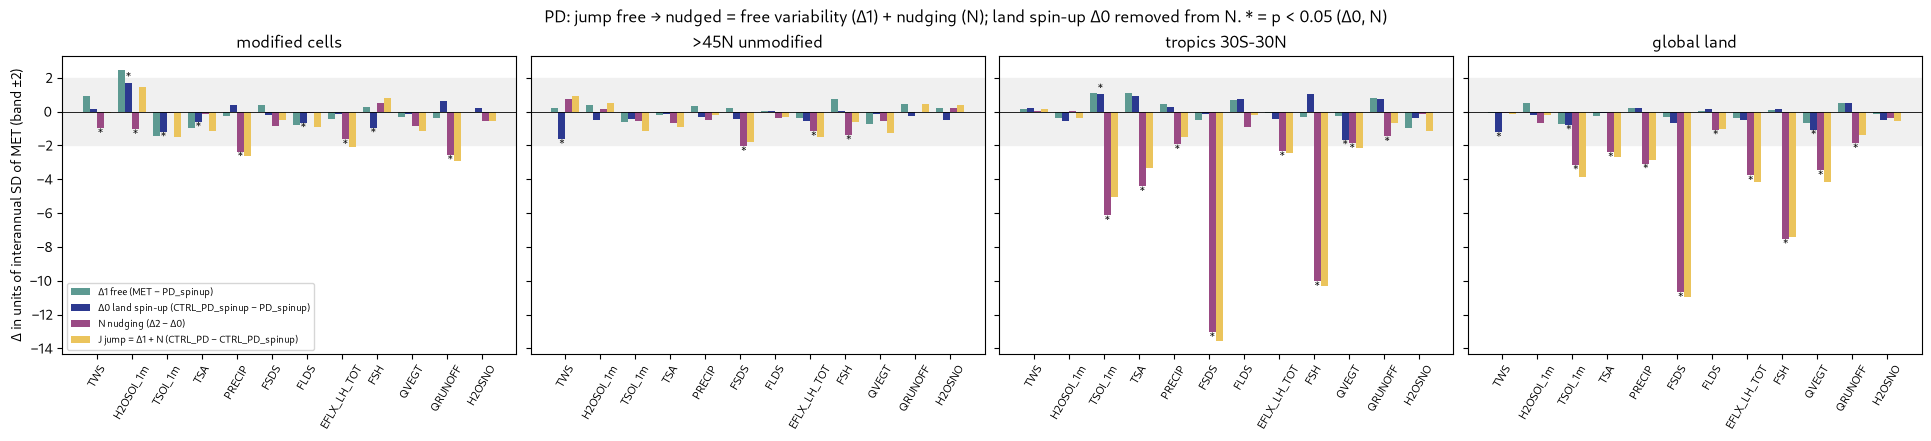

In [7]:
rows = []
for region in REGIONS:
    for v in VARS:
        spin = SERIES['PD_spinup', region, v].sel(year=window('PD_spinup'))
        cspin = SERIES['CTRL_PD_spinup', region, v].sel(year=window('CTRL_PD_spinup'))
        met = SERIES['MET', region, v].sel(year=window('MET'))
        nud = SERIES['CTRL_PD', region, v].sel(year=window('CTRL_PD'))
        assert list(met.year.values) == list(nud.year.values)
        sd = float(met.std(ddof=1))
        d0, d1, d2 = float(cspin.mean() - spin.mean()), float(met.mean() - spin.mean()), float(nud.mean() - met.mean())
        jump = float(nud.mean() - cspin.mean())
        n = d2 - d0
        assert abs(d1 + n - jump) < 1e-9 * max(1, abs(jump))
        pd_ = (nud - met).values
        se2, df2 = pd_.std(ddof=1) / np.sqrt(len(pd_)), len(pd_) - 1
        w = stats.ttest_ind(cspin.values, spin.values, equal_var=False)
        se0 = np.sqrt(cspin.var(ddof=1) / cspin.size + spin.var(ddof=1) / spin.size).item()
        se_n = np.sqrt(se2 ** 2 + se0 ** 2)
        rows.append(dict(region=region, variable=v, units=units_of(v), spinup=float(spin.mean()),
                         ctrl_spinup=float(cspin.mean()), met=float(met.mean()), nudged=float(nud.mean()),
                         d1_free=d1, d0_land_spinup=d0, d2_nudging_plus_land=d2, n_nudging=n, jump=jump, iav_sd=sd,
                         d1_in_iav=d1 / sd, d0_in_iav=d0 / sd, d2_in_iav=d2 / sd, n_in_iav=n / sd, jump_in_iav=jump / sd,
                         p_d2_paired=stats.ttest_rel(nud.values, met.values).pvalue, p_d0_welch=w.pvalue,
                         p_n=2 * stats.t.sf(abs(n) / se_n, min(df2, w.df)) if se_n > 0 else np.nan))
decomp = pd.DataFrame(rows)
decomp.to_csv(OUT / 'pd_jump_decomposition.csv', index=False)
display(decomp.set_index(['region', 'variable'])[['units', 'd1_free', 'd0_land_spinup', 'd2_nudging_plus_land', 'n_nudging', 'jump',
                                                 'n_in_iav', 'jump_in_iav', 'p_d2_paired', 'p_d0_welch', 'p_n']].round(4))

TERMS = [('d1_in_iav', 'Δ1 free (MET − PD_spinup)', TEAL, None),
         ('d0_in_iav', 'Δ0 land spin-up (CTRL_PD_spinup − PD_spinup)', NAVY, 'p_d0_welch'),
         ('n_in_iav', 'N nudging (Δ2 − Δ0)', PLUM, 'p_n'),
         ('jump_in_iav', 'J jump = Δ1 + N (CTRL_PD − CTRL_PD_spinup)', GOLD, None)]
fig, axes = plt.subplots(1, len(REGIONS), figsize=(4.8 * len(REGIONS), 4.3), sharey=True, layout='constrained')
x = np.arange(len(VARS))
wd = 0.2
for ax, region in zip(axes, REGIONS):
    sub = decomp[decomp.region == region].set_index('variable').loc[VARS]
    for k, (col, label, color, pcol) in enumerate(TERMS):
        bars = ax.bar(x + (k - 1.5) * wd, sub[col], wd, color=color, label=label)
        if pcol:
            for b, p in zip(bars, sub[pcol]):
                if p < 0.05:
                    ax.text(b.get_x() + b.get_width() / 2, b.get_height(), '*', ha='center', fontsize=8,
                            va='bottom' if b.get_height() > 0 else 'top')
    ax.axhline(0, color='k', lw=0.6)
    ax.axhspan(-2, 2, color='0.94', zorder=0)
    ax.set(xticks=x, title=region)
    ax.set_xticklabels(VARS, rotation=60, fontsize=8)
axes[0].set_ylabel('Δ in units of interannual SD of MET (band ±2)')
axes[0].legend(fontsize=7, loc='lower left')
fig.suptitle('PD: jump free → nudged = free variability (Δ1) + nudging (N); land spin-up Δ0 removed from N. * = p < 0.05 (Δ0, N)')
fig.savefig(OUT / 'fig2_pd_decomposition.png', dpi=150)
plt.show()

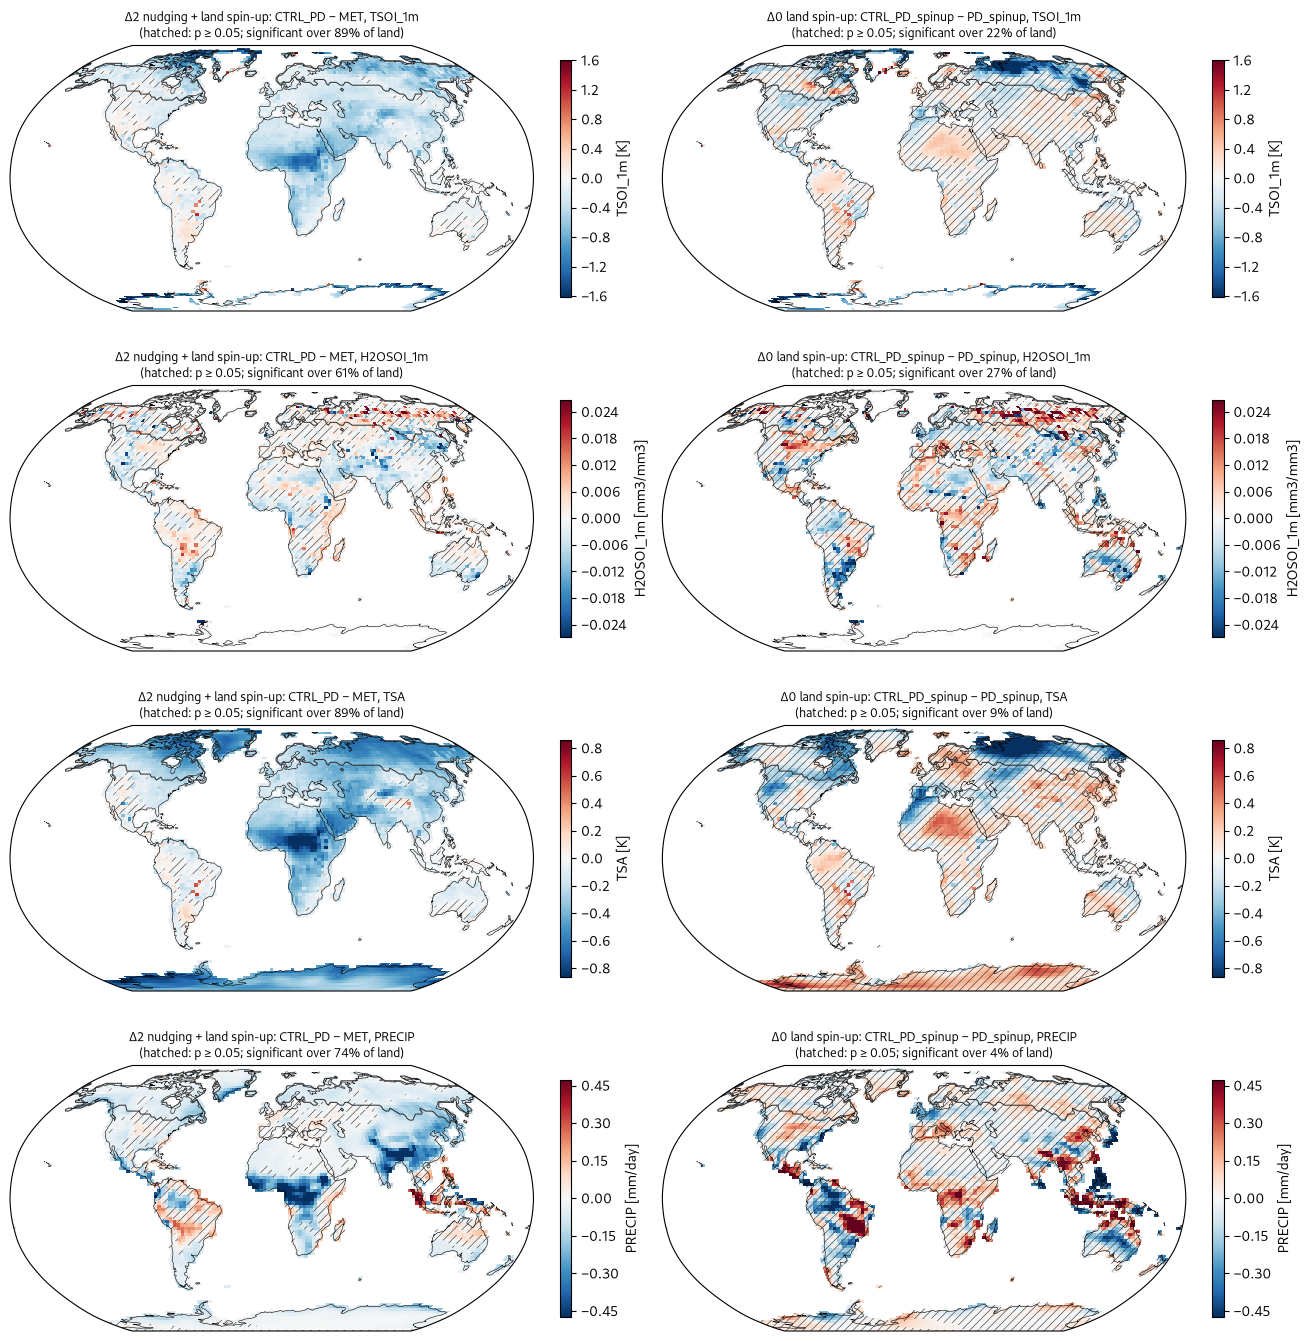

In [8]:
MAP_VARS = ['TSOI_1m', 'H2OSOI_1m', 'TSA', 'PRECIP']
COLS = {'Δ2 nudging + land spin-up: CTRL_PD − MET': ('CTRL_PD', 'MET', True),
        'Δ0 land spin-up: CTRL_PD_spinup − PD_spinup': ('CTRL_PD_spinup', 'PD_spinup', False)}
fig, axes = plt.subplots(len(MAP_VARS), 2, figsize=(13, 3.4 * len(MAP_VARS)), subplot_kw=dict(projection=ccrs.Robinson()),
                         layout='constrained')
for i, v in enumerate(MAP_VARS):
    fields = {}
    for title, (a, b, paired) in COLS.items():
        fa, fb = scaled(a, v).sel(year=window(a)), scaled(b, v).sel(year=window(b))
        with warnings.catch_warnings(), np.errstate(all='ignore'):
            warnings.simplefilter('ignore')
            p = (stats.ttest_rel(fa.values, fb.values, axis=0) if paired
                 else stats.ttest_ind(fa.values, fb.values, axis=0, equal_var=False)).pvalue
        fields[title] = ((fa.mean('year') - fb.mean('year')).where(LAND), p)
    lim = max(float(np.nanpercentile(abs(d), 98)) for d, _ in fields.values())  # shared scale per variable
    for j, (title, (d, p)) in enumerate(fields.items()):
        ax = axes[i, j]
        m = ax.pcolormesh(d.lon, d.lat, d, transform=ccrs.PlateCarree(), cmap='RdBu_r', vmin=-lim, vmax=lim, shading='nearest')
        sig = (p < 0.05) & np.isfinite(d.values)
        hatch_nonsig(ax, d.lat.values, d.lon.values, sig, np.isfinite(d.values))
        ax.contour(mask.lon, mask.lat, mask.astype(int), levels=[0.5], colors=INK, linewidths=0.7, transform=ccrs.PlateCarree())
        ax.coastlines(lw=0.4)
        ax.set_global()
        cb = fig.colorbar(m, ax=ax, shrink=0.75, label=f'{v} [{units_of(v)}]')
        sym_ticks(cb, lim)
        w = W.where(LAND & np.isfinite(d))
        ax.set_title(f'{title}, {v}\n(hatched: p ≥ 0.05; significant over {float(w.where(sig).sum() / w.sum()):.0%} of land)', fontsize=9)
fig.savefig(OUT / 'fig3_pd_nudging_effect_maps.png', dpi=150)
plt.show()

## 4. Total jump free → nudged: PD vs FUT, CTRL and LCC branches

Jump = nudged run (2001–2014) − its own coupled spin-up (last 10 years), in units of the nudged run's interannual SD.
- PD CTRL: this is J = Δ1 + N from §3.
- FUT: the jump cannot be split, because there is no free FUT met run. FUT is nudged to **PD** winds by design, so its jump also contains the mismatch between PD circulation and 2100 thermodynamics (b).

pair                         PD CTRL  PD LCC  FUT CTRL  FUT LCC
variable    region                                             
EFLX_LH_TOT >45N unmodified  -0.6208 -0.8777   -0.2361  -0.4843
            global land      -1.1478 -1.0944   -1.3776  -1.2525
            modified cells   -0.8010 -0.9648   -1.5190  -1.7010
            tropics 30S-30N  -1.4218 -1.2087   -1.8726  -1.3852
FLDS        >45N unmodified  -0.4870 -1.1688   -1.5247  -2.0598
            global land      -0.5308 -0.4536   -0.7751  -1.0949
            modified cells   -1.9992 -2.9360   -3.2380  -3.9118
            tropics 30S-30N  -0.1458  0.5586   -0.1847  -0.2936
FSDS        >45N unmodified  -2.1318 -3.1761   -5.5920  -5.1478
            global land      -4.7022 -5.3463   -7.1515  -6.8061
            modified cells   -0.4604 -1.0070   -4.2769  -3.8548
            tropics 30S-30N  -7.7786 -8.3463  -10.8727 -10.6742
FSH         >45N unmodified  -0.3350 -0.5971   -1.0212  -0.8883
            global land      -1.5727 -1.7951   -1.8829  -1.9023
            modified cells    0.3434 -0.0754   -0.2474  -0.2477
            tropics 30S-30N  -2.9940 -3.1158   -3.7579  -3.9285
H2OSNO      >45N unmodified   1.0175  1.2843   -7.0342  -9.6929
            global land      -0.2683 -0.1597   -1.9299  -1.9507
            modified cells   -1.7609 -1.1382   -5.2983  -4.3370
            tropics 30S-30N  -0.0278 -0.0201    0.0037   0.0032
H2OSOI_1m   >45N unmodified   0.0009  0.0015    0.0083   0.0075
            global land      -0.0002  0.0007    0.0017   0.0019
            modified cells    0.0023  0.0043    0.0062   0.0050
            tropics 30S-30N  -0.0004  0.0001   -0.0012  -0.0001
PRECIP      >45N unmodified  -0.0106 -0.0209    0.1054   0.0811
            global land      -0.0693 -0.0520   -0.0151  -0.0112
            modified cells   -0.0903 -0.0867   -0.0073   0.0006
            tropics 30S-30N  -0.0736 -0.0412   -0.0294  -0.0168
QRUNOFF     >45N unmodified   0.0169  0.0139    0.1243   0.1025
            global land      -0.0255 -0.0142    0.0347   0.0315
            modified cells   -0.0692 -0.0558    0.0492   0.0585
            tropics 30S-30N  -0.0226 -0.0047    0.0272   0.0242
QVEGT       >45N unmodified  -0.0120 -0.0148   -0.0094  -0.0144
            global land      -0.0141 -0.0155   -0.0102  -0.0100
            modified cells   -0.0113 -0.0164   -0.0221  -0.0247
            tropics 30S-30N  -0.0137 -0.0145   -0.0089  -0.0052
TSA         >45N unmodified  -0.3134 -0.4767   -0.9472  -1.0345
            global land      -0.3032 -0.3494   -0.5627  -0.6105
            modified cells   -0.5970 -0.7872   -1.1609  -1.2886
            tropics 30S-30N  -0.2284 -0.2043   -0.3774  -0.3972
TSOI_1m     >45N unmodified  -0.2676 -0.4318   -0.9702  -1.0192
            global land      -0.2900 -0.3421   -0.5532  -0.5732
            modified cells   -0.4338 -0.6482   -0.8272  -0.8863
            tropics 30S-30N  -0.2991 -0.2730   -0.4577  -0.4798
TWS         >45N unmodified   7.4203  5.5901   35.1740  29.2146
            global land      -0.7430  1.0150    9.3253   8.9983
            modified cells   -0.4847  4.3832   23.8896  22.7531
            tropics 30S-30N   1.1583  3.0113   -0.8691   2.0606

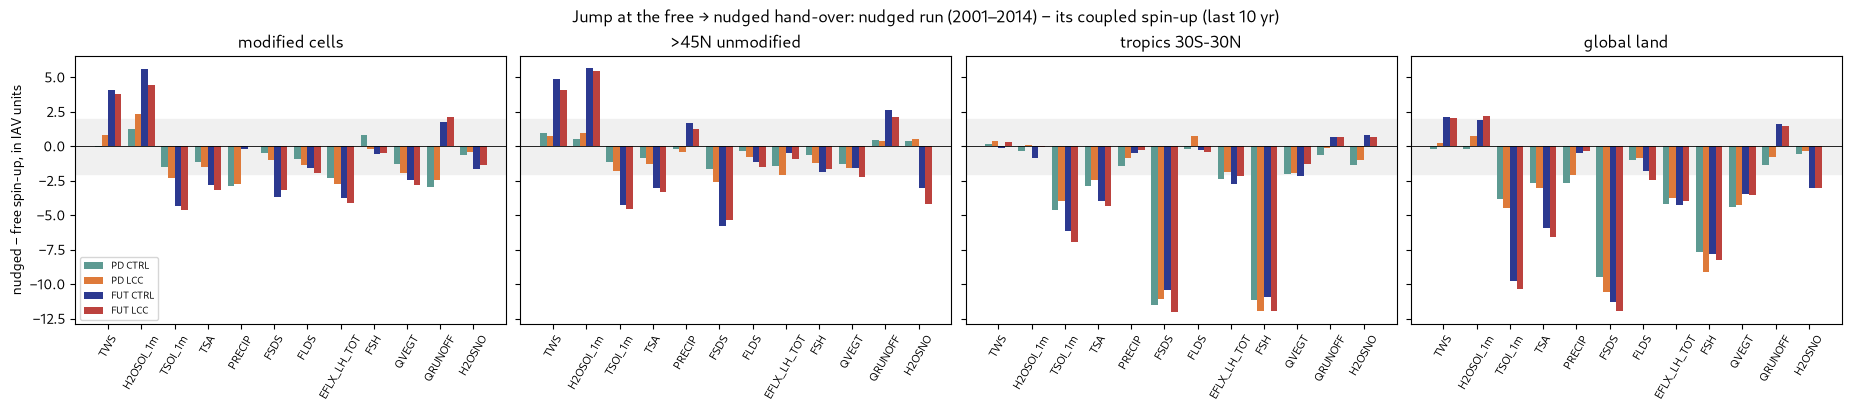

In [9]:
PAIRS = {'PD CTRL': ('CTRL_PD_spinup', 'CTRL_PD'), 'PD LCC': ('LCC_PD_spinup', 'LCC_PD'),
         'FUT CTRL': ('CTRL_FUT_spinup', 'CTRL_FUT'), 'FUT LCC': ('LCC_FUT_spinup', 'LCC_FUT')}
rows = []
for name, (free, nud) in PAIRS.items():
    for region in REGIONS:
        for v in VARS:
            if (free, region, v) not in SERIES:
                continue
            f = SERIES[free, region, v].sel(year=window(free))
            n = SERIES[nud, region, v].sel(year=window(nud))
            sd = float(n.std(ddof=1))
            rows.append(dict(pair=name, region=region, variable=v, units=units_of(v),
                             jump=float(n.mean() - f.mean()), jump_in_iav=float(n.mean() - f.mean()) / sd,
                             p_welch=stats.ttest_ind(n.values, f.values, equal_var=False).pvalue))
jumps = pd.DataFrame(rows)
jumps.to_csv(OUT / 'jumps_free_to_nudged.csv', index=False)
display(jumps.pivot_table(index=['variable', 'region'], columns='pair', values='jump')[list(PAIRS)].round(4))

fig, axes = plt.subplots(1, len(REGIONS), figsize=(4.6 * len(REGIONS), 4), sharey=True, layout='constrained')
colors = {'PD CTRL': TEAL, 'PD LCC': ORANGE, 'FUT CTRL': NAVY, 'FUT LCC': RED}
x = np.arange(len(VARS))
for ax, region in zip(axes, REGIONS):
    sub = jumps[jumps.region == region].set_index(['pair', 'variable']).jump_in_iav
    for k, name in enumerate(PAIRS):
        vals = [sub.get((name, v), np.nan) for v in VARS]
        ax.bar(x + (k - 1.5) * 0.2, vals, 0.2, color=colors[name], label=name)
    ax.axhline(0, color='k', lw=0.6)
    ax.axhspan(-2, 2, color='0.94', zorder=0)
    ax.set(xticks=x, title=region)
    ax.set_xticklabels(VARS, rotation=60, fontsize=8)
axes[0].set_ylabel('nudged − free spin-up, in IAV units')
axes[0].legend(fontsize=7)
fig.suptitle('Jump at the free → nudged hand-over: nudged run (2001–2014) − its coupled spin-up (last 10 yr)')
fig.savefig(OUT / 'fig4_jumps_pd_fut.png', dpi=150)
plt.show()

## 5. Drift during the nudged years: is it the same in CTRL and LCC?

For each period, region and variable, over 2001–2014:
- OLS trend of CTRL, of LCC, and of the **difference series LCC − CTRL**;
- the standard error of the difference trend, corrected for lag-1 autocorrelation of the residuals (n_eff = n(1 − r₁)/(1 + r₁), at least 3);
- **flag `drift_differs` if p < 0.05.** If the drift is the same in both members, it cancels in LCC − CTRL.

With 14 years, trends are still uncertain: about 1 in 20 tests will be flagged by chance.

In [10]:
def trend_test(y):
    x = y.year.values.astype(float)
    slope, icpt = np.polyfit(x, y.values, 1)
    res = y.values - (slope * x + icpt)
    n = len(x)
    r1 = np.corrcoef(res[:-1], res[1:])[0, 1] if n > 3 else 0.0
    n_eff = float(np.clip(n * (1 - r1) / (1 + r1), 3, n))
    se = np.sqrt(np.sum(res ** 2) / (n - 2) / np.sum((x - x.mean()) ** 2)) * np.sqrt((n - 2) / max(n_eff - 2, 1))
    p = 2 * stats.t.sf(abs(slope / se), max(n_eff - 2, 1)) if se > 0 else np.nan
    return 10 * slope, 10 * se, p, n_eff

rows = []
for period in ('PD', 'FUT'):
    for region in REGIONS:
        for v in VARS:
            c = SERIES[f'CTRL_{period}', region, v].sel(year=slice(*NUDGED_YEARS))
            l = SERIES[f'LCC_{period}', region, v].sel(year=slice(*NUDGED_YEARS))
            tc, tl = trend_test(c)[0], trend_test(l)[0]
            td, se, p, neff = trend_test(l - c)
            rows.append(dict(period=period, region=region, variable=v, units=units_of(v) + '/decade',
                             trend_CTRL=tc, trend_LCC=tl, trend_diff=td, se_diff=se, n_eff=neff, p_diff=p,
                             diff_vs_member=abs(td) / max(abs(tc), abs(tl), 1e-30), drift_differs=p < 0.05))
drift = pd.DataFrame(rows)
drift.to_csv(OUT / 'drift_same_in_both_members.csv', index=False)
print(f"Flagged (p < 0.05): {int(drift.drift_differs.sum())} of {len(drift)} tests (≈{0.05 * len(drift):.0f} expected by chance)")
display(drift[drift.variable.isin(SHORT)].set_index(['period', 'region', 'variable']).round(4))
display(drift[drift.drift_differs].set_index(['period', 'region', 'variable']).round(4))

Flagged (p < 0.05): 4 of 96 tests (≈5 expected by chance)


units  trend_CTRL  trend_LCC  \
period region          variable                                           
PD     modified cells  TWS             mm/decade      3.2318     2.4726   
                       H2OSOI_1m  mm3/mm3/decade      0.0017     0.0019   
                       TSOI_1m          K/decade     -0.1715    -0.1770   
       >45N unmodified TWS             mm/decade     -9.8006   -10.0063   
                       H2OSOI_1m  mm3/mm3/decade     -0.0017    -0.0021   
                       TSOI_1m          K/decade     -0.1271    -0.1579   
       tropics 30S-30N TWS             mm/decade      4.6885     5.6448   
                       H2OSOI_1m  mm3/mm3/decade     -0.0001     0.0000   
                       TSOI_1m          K/decade      0.0340     0.0400   
       global land     TWS             mm/decade      1.5154     2.2037   
                       H2OSOI_1m  mm3/mm3/decade      0.0002     0.0002   
                       TSOI_1m          K/decade     -0.0404    -0.0449   
FUT    modified cells  TWS             mm/decade     -2.9081    -4.0575   
                       H2OSOI_1m  mm3/mm3/decade     -0.0001    -0.0004   
                       TSOI_1m          K/decade     -0.1148    -0.1087   
       >45N unmodified TWS             mm/decade     -2.8610    -3.0889   
                       H2OSOI_1m  mm3/mm3/decade     -0.0022    -0.0020   
                       TSOI_1m          K/decade     -0.1393    -0.1471   
       tropics 30S-30N TWS             mm/decade     -3.1662    -3.3739   
                       H2OSOI_1m  mm3/mm3/decade     -0.0008    -0.0008   
                       TSOI_1m          K/decade      0.0358     0.0371   
       global land     TWS             mm/decade     -0.8648    -1.3585   
                       H2OSOI_1m  mm3/mm3/decade     -0.0005    -0.0006   
                       TSOI_1m          K/decade     -0.0318    -0.0308   

                                  trend_diff  se_diff    n_eff  p_diff  \
period region          variable                                          
PD     modified cells  TWS           -0.7592   0.5652   7.4609  0.2323   
                       H2OSOI_1m      0.0002   0.0001  14.0000  0.1901   
                       TSOI_1m       -0.0056   0.0128   7.8389  0.6796   
       >45N unmodified TWS           -0.2056   0.4372   7.2254  0.6570   
                       H2OSOI_1m     -0.0005   0.0005   3.0000  0.5188   
                       TSOI_1m       -0.0307   0.0172   9.6444  0.1143   
       tropics 30S-30N TWS            0.9563   0.5508   7.4978  0.1377   
                       H2OSOI_1m      0.0001   0.0001  10.6403  0.4087   
                       TSOI_1m        0.0060   0.0059  14.0000  0.3292   
       global land     TWS            0.6883   0.2366   8.8591  0.0232   
                       H2OSOI_1m      0.0000   0.0000  14.0000  0.7266   
                       TSOI_1m       -0.0045   0.0026  14.0000  0.1073   
FUT    modified cells  TWS           -1.1494   0.5460   5.5199  0.1125   
                       H2OSOI_1m     -0.0004   0.0006   3.2547  0.5885   
                       TSOI_1m        0.0062   0.0091  12.1988  0.5115   
       >45N unmodified TWS           -0.2279   0.6313   4.8962  0.7428   
                       H2OSOI_1m      0.0002   0.0002   5.8018  0.3818   
                       TSOI_1m       -0.0078   0.0049  14.0000  0.1398   
       tropics 30S-30N TWS           -0.2077   0.6877   9.2819  0.7711   
                       H2OSOI_1m      0.0001   0.0002   4.7985  0.6889   
                       TSOI_1m        0.0014   0.0083  14.0000  0.8712   
       global land     TWS           -0.4936   0.3675   7.5676  0.2314   
                       H2OSOI_1m     -0.0001   0.0002   3.3069  0.7751   
                       TSOI_1m        0.0010   0.0042  14.0000  0.8093   

                                  diff_vs_member  drift_differs  
period region          variable                                  
PD     modified cells  TWS         

units  trend_CTRL  trend_LCC  \
period region         variable                                            
PD     global land    TWS              mm/decade      1.5154     2.2037   
FUT    modified cells EFLX_LH_TOT   W/m^2/decade      0.3042     0.1904   
                      QVEGT        mm/day/decade      0.0093     0.0071   
       global land    QVEGT        mm/day/decade      0.0019     0.0012   

                                   trend_diff  se_diff    n_eff  p_diff  \
period region         variable                                            
PD     global land    TWS              0.6883   0.2366   8.8591  0.0232   
FUT    modified cells EFLX_LH_TOT     -0.1138   0.0418  14.0000  0.0184   
                      QVEGT           -0.0022   0.0005  14.0000  0.0013   
       global land    QVEGT           -0.0006   0.0003  14.0000  0.0387   

                                   diff_vs_member  drift_differs  
period region         variable                                    
PD     global land    TWS                  0.3123           True  
FUT    modified cells EFLX_LH_TOT          0.3741           True  
                      QVEGT                0.2376           True  
       global land    QVEGT                0.3455           True

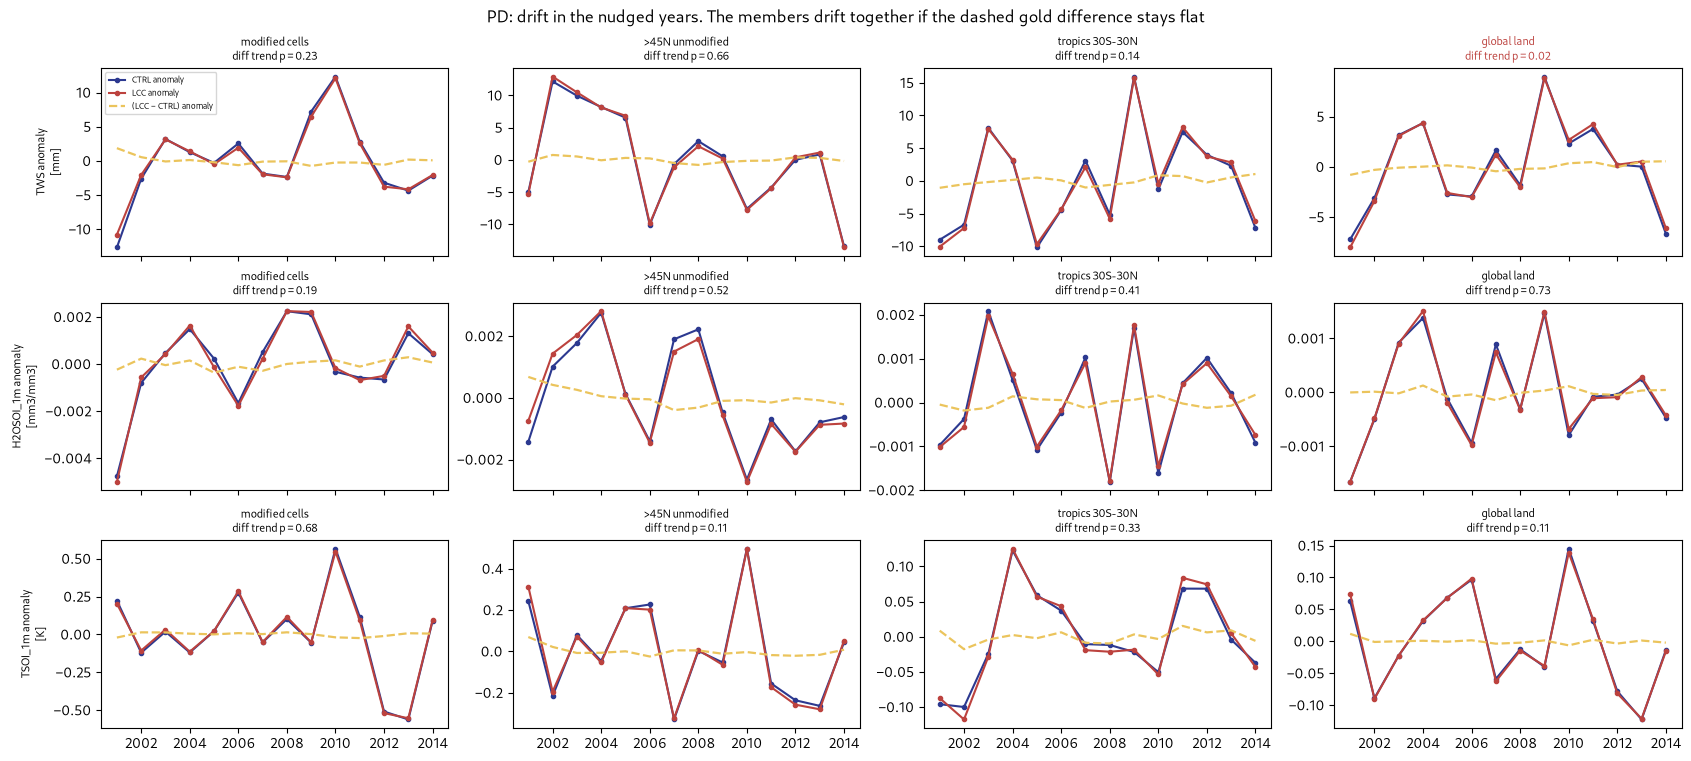

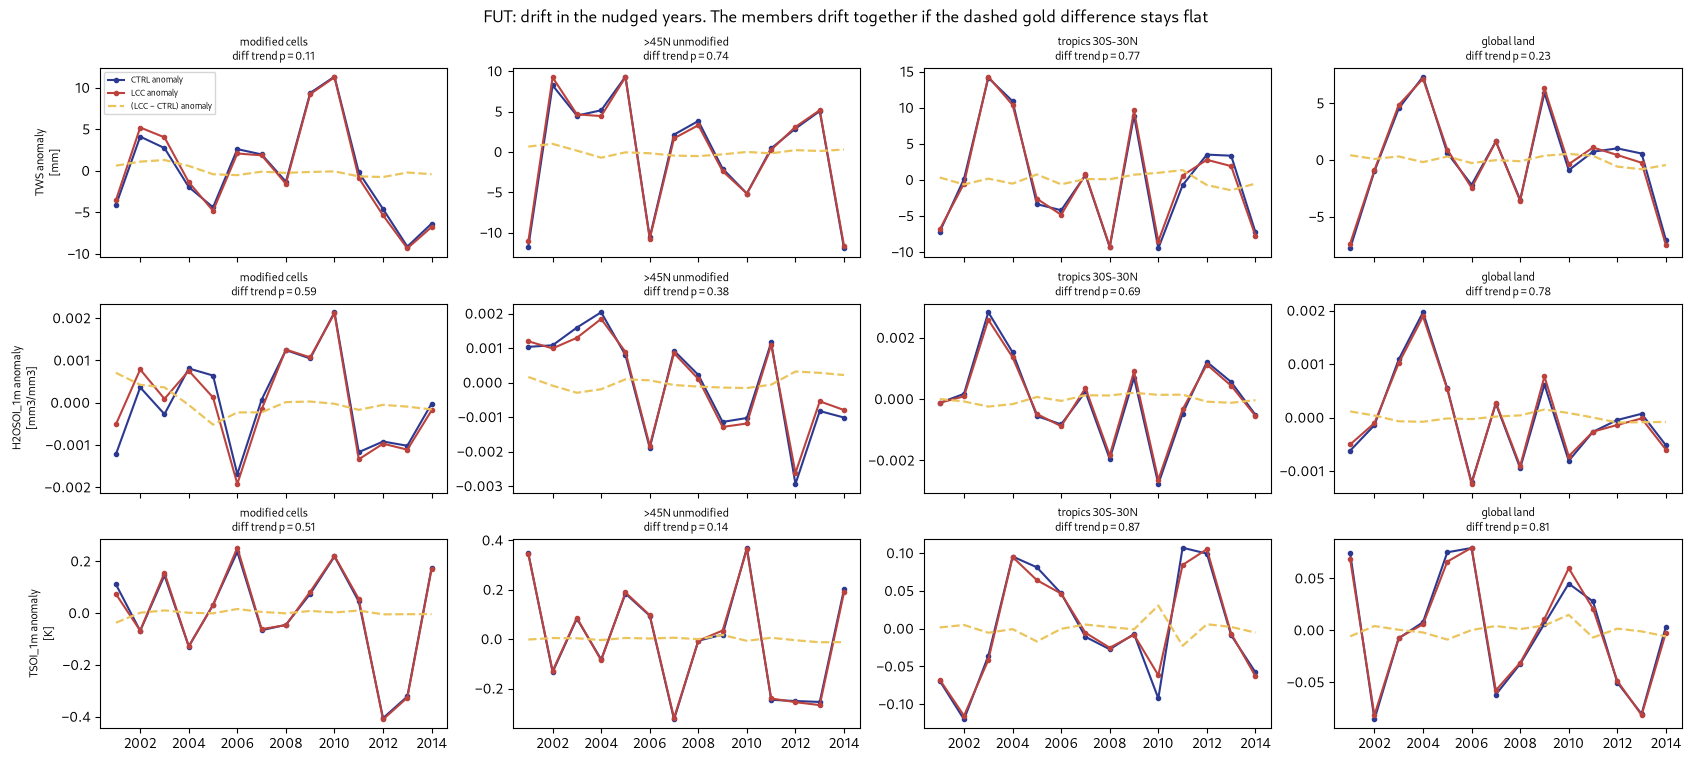

In [11]:
for period in ('PD', 'FUT'):
    fig, axes = plt.subplots(len(SHORT), len(REGIONS), figsize=(4.2 * len(REGIONS), 2.5 * len(SHORT)),
                             sharex=True, layout='constrained')
    for i, v in enumerate(SHORT):
        for j, region in enumerate(REGIONS):
            ax = axes[i, j]
            c = SERIES[f'CTRL_{period}', region, v].sel(year=slice(*NUDGED_YEARS))
            l = SERIES[f'LCC_{period}', region, v].sel(year=slice(*NUDGED_YEARS))
            ax.plot(c.year, c - c.mean(), 'o-', ms=3, color=COLOR['CTRL'], label='CTRL anomaly')
            ax.plot(l.year, l - l.mean(), 'o-', ms=3, color=COLOR['LCC'], label='LCC anomaly')
            d = l - c
            ax.plot(d.year, d - d.mean(), '--', color=GOLD, lw=1.6, label='(LCC − CTRL) anomaly')
            row = drift.set_index(['period', 'region', 'variable']).loc[(period, region, v)]
            ax.set_title(f'{region}\ndiff trend p = {row.p_diff:.2f}', fontsize=8, color=RED if row.drift_differs else 'k')
            if j == 0:
                ax.set_ylabel(f'{v} anomaly\n[{units_of(v)}]', fontsize=8)
    axes[0, 0].legend(fontsize=6)
    fig.suptitle(f'{period}: drift in the nudged years. The members drift together if the dashed gold difference stays flat')
    fig.savefig(OUT / f'fig5_drift_{period}.png', dpi=150)
    plt.show()

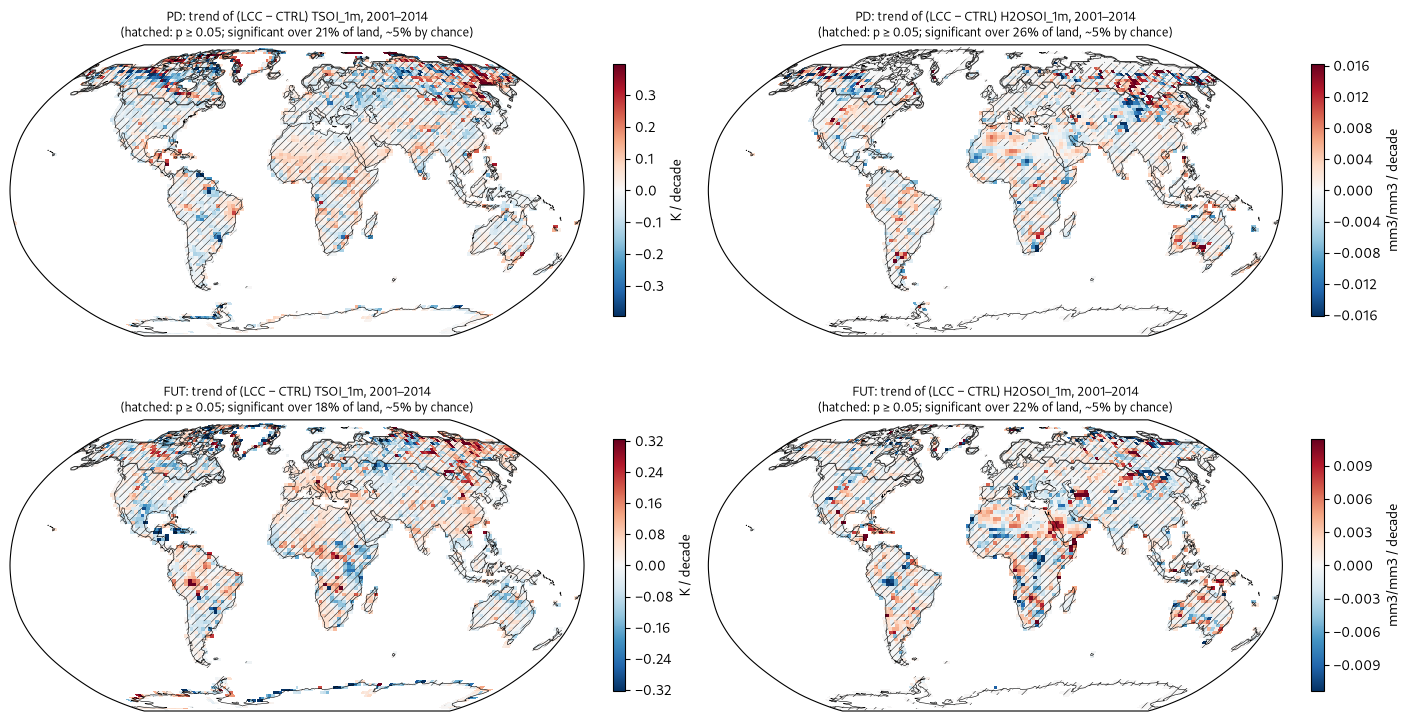

In [12]:
def cell_trend(field):
    # OLS slope per decade and plain p-value per cell (no autocorrelation correction in maps)
    x = field.year.values.astype(float)
    xa = x - x.mean()
    y = field.values
    slope = np.tensordot(xa, y - y.mean(0), axes=(0, 0)) / np.sum(xa ** 2)
    res = y - y.mean(0) - slope * xa[:, None, None]
    se = np.sqrt((res ** 2).sum(0) / (len(x) - 2) / np.sum(xa ** 2))
    with np.errstate(all='ignore'):
        p = 2 * stats.t.sf(abs(slope / se), len(x) - 2)
    return 10 * slope, p

fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), subplot_kw=dict(projection=ccrs.Robinson()), layout='constrained')
for i, period in enumerate(['PD', 'FUT']):
    for j, v in enumerate(['TSOI_1m', 'H2OSOI_1m']):
        ax = axes[i, j]
        d = (scaled(f'LCC_{period}', v) - scaled(f'CTRL_{period}', v)).sel(year=slice(*NUDGED_YEARS))
        tr, p = cell_trend(d)
        tr = xr.DataArray(tr, coords=dict(lat=d.lat, lon=d.lon)).where(LAND)
        lim = float(np.nanpercentile(abs(tr), 98))
        m = ax.pcolormesh(tr.lon, tr.lat, tr, transform=ccrs.PlateCarree(), cmap='RdBu_r', vmin=-lim, vmax=lim, shading='nearest')
        sig = (p < 0.05) & np.isfinite(tr.values)
        hatch_nonsig(ax, tr.lat.values, tr.lon.values, sig, np.isfinite(tr.values))
        ax.contour(mask.lon, mask.lat, mask.astype(int), levels=[0.5], colors=INK, linewidths=0.7, transform=ccrs.PlateCarree())
        ax.coastlines(lw=0.4)
        ax.set_global()
        w = W.where(LAND & np.isfinite(tr))
        sym_ticks(fig.colorbar(m, ax=ax, shrink=0.7, label=f'{units_of(v)} / decade'), lim)
        ax.set_title(f'{period}: trend of (LCC − CTRL) {v}, 2001–2014\n(hatched: p ≥ 0.05; significant over {float(w.where(sig).sum() / w.sum()):.0%} of land, ~5% by chance)', fontsize=9)
fig.savefig(OUT / 'fig6_trend_of_difference_maps.png', dpi=150)
plt.show()

## Summary (new chain, run 2026-11-03; outputs in this notebook and in `impact_of_nudging_on_land_outputs/`)

👉 **Same picture as on the old chain. The jump at the free → nudged hand-over is mainly nudging itself: the land gets less sun, so it is cooler and evaporates less. CTRL and LCC jump the same way, so the jump cancels in LCC − CTRL. In the new chain, the nudged-year drift no longer differs between CTRL and LCC, because both now have a land-only spin-up.**

**1. Set-up (a, §1).** All four nudged runs use the same PD met file, `met_nudge_only_uvps = .true.` and `met_rlx_time = 6`. FUT is nudged to PD winds by design.

**2. PD decomposition (a, §3, `pd_jump_decomposition.csv`).** Global land, 2001–2014. IAV = interannual SD of MET.

| | FSDS [W m⁻²] | FSH | LH | TSA [K] | TSOI@1 m [K] | PRECIP [mm/day] | TWS [mm] |
|---|---|---|---|---|---|---|---|
| N nudging (Δ2 − Δ0) | −4.6 (−10.7 IAV) | −1.6 (−7.5) | −1.0 (−3.8) | −0.27 (−2.4) | −0.24 (−3.1) | −0.07 (−3.1) | −0.3 (−0.1) |
| Δ0 land spin-up | −0.3 (−0.7) | 0.0 | −0.1 | −0.01 | −0.06 (−0.8) | 0.00 | −5.2 (−1.2) |
| Δ1 free variability | −0.1 | 0.0 | −0.1 | −0.03 | −0.05 (−0.7) | 0.00 | −0.4 |
| J jump = Δ1 + N | −4.7 (−11.0) | −1.6 (−7.4) | −1.1 (−4.2) | −0.30 (−2.7) | −0.29 (−3.9) | −0.07 (−2.9) | −0.7 (−0.2) |

- The nudging effect N is the same size as on the old chain (old Δ2: FSDS −4.9, TSOI −0.28 K). It is largest in the tropics: FSDS −7.5 W m⁻² (−13 IAV), TSOI −0.36 K (−6.1 IAV), FSH −2.9 W m⁻² (−10 IAV).
- Reading (b): relaxing u, v and PS every 6 h gives **more cloud and less sunshine at the surface**, so the land is cooler and evaporates less.
- **Land spin-up Δ0 is small in the regional means** (|Δ0| < 2 IAV everywhere; largest TWS >45°N unmodified −13 mm, −1.6 IAV). Locally it is not small (fig. 3, right): TSA and TSOI are up to ~1 K cooler over Siberia, significant over 9 % (TSA) and 22 % (TSOI) of land. Free vs free, so weather noise is part of it (b).
- **Modified cells:** the jump is mostly free variability. Δ1 gives H2OSOI +2.5 IAV and TSOI −1.4 IAV; Δ0 adds a similar amount. Nudging there mainly lowers precipitation (−2.4 IAV), runoff (−2.6) and latent heat (−1.6).

**3. FUT jump (a, §4, `jumps_free_to_nudged.csv`).** In IAV units of the nudged run, CTRL branch (LCC within ~1 IAV):

| Variable | Region | PD | FUT |
|---|---|---|---|
| TSOI@1 m | global land | −3.8 | **−9.8** |
| FSDS | global land | −9.5 | −11.3 |
| H2OSOI@1 m | >45°N unmodified | +0.5 | **+5.7** |
| H2OSOI@1 m | modified cells | +1.3 | **+5.6** |
| TWS | modified cells | −0.1 | +4.1 |
| H2OSNO | >45°N unmodified | +0.4 | −3.0 |

Reading (b): on top of the nudging effect, the PD winds bring PD moisture transport into a 2100 climate. This makes the boreal soils wetter and leaves less snow, as on the old chain. It cannot be split further: there is no free FUT met run (c).
**In both periods the CTRL and LCC jumps are nearly identical** (e.g. FUT TSOI global −9.8 vs −10.4 IAV), so the jump cancels in LCC − CTRL (a).

**4. Is the drift the same in both members? (a, §5, `drift_same_in_both_members.csv`).** 4 of 96 tests are flagged at p < 0.05, against ~5 expected by chance (old chain: 9 of 96).
- **Short-term variables:** only PD global-land TWS is flagged (LCC − CTRL trend +0.7 mm/decade, against member trends of +1.5 and +2.2). H2OSOI and TSOI are never flagged.
- The old-chain flag on TWS and snow at >45°N (LCC losing less water than CTRL) is **gone**. That is consistent with it having come from the old asymmetric spin-up, when only LCC had a land-only spin-up (b).
- **Per-cell maps (fig. 6) are less reassuring:** the trend of LCC − CTRL in TSOI@1 m and H2OSOI@1 m is significant over 18–26 % of land, against ~5 % expected by chance. Those p-values are not corrected for autocorrelation or multiple testing, so the excess is an upper bound (b). The cells are scattered, with no coherent pattern over the modified region.
- Other flags: FUT transpiration (modified cells, global land) and FUT modified-cell latent heat. These are small differences in the region where LCC ≠ CTRL is expected.

**Implications (b).**
- LCC − CTRL in the same period is robust to the nudging effect and to the nudged-year drift.
- **Absolute values** of nudged runs, and comparisons of nudged vs free runs, are biased by about −0.3 K (soil and air temperature) and −5 W m⁻² surface solar (global land, PD). The bias is larger in FUT.
- **FUT − PD** comparisons of land variables include the effect of PD winds in a 2100 climate.

**Limits:** N assumes the nudging and land spin-up effects add up; Δ0 and Δ1 compare 10 free years against 14 nudged or MET years; the maps have no autocorrelation or multiple-testing correction (hatching = p ≥ 0.05); the FUT split is not possible.
